# Prediksi Risiko Stres Panas — Learning Problem & EDA

**Anggota:** Novandy Triarto Wahyono (244311053) dan Alivia Rizka Wardani (244311035)  
**Program Studi:** Teknologi Rekayasa Perangkat Lunak — Data Science

| Komponen | Formulasi |
|---|---|
| **Target** | Kelas risiko stres panas satu hari ke depan (`heat_risk_besok`): Low, Moderate, High, Extreme. Dibentuk dari `target_apparent_temp_besok` dengan ambang tropis 33/36/39°C. |
| **Objective** | Klasifikasi multikelas deret waktu; meminimalkan categorical cross-entropy dan menilai terutama Macro F1 serta Recall kelas High/Extreme. |
| **Data** | Cuaca harian ERA5-Land/Open-Meteo dan ONI NOAA untuk tujuh kota di Indonesia, 2021-01-01–2026-11-10; 14.980 baris dan 29 kolom sebelum cleaning. |

Data bersifat non-i.i.d.; pemisahan train, validation, dan test dilakukan secara kronologis, bukan acak.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

DATA_PATH = Path("../dataset_cuaca_elnino_merged.csv")
FIGURE_DIR = Path("../reports/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)
print(f"Dataset: {DATA_PATH.resolve()}")
print(f"Dimensi awal: {df.shape[0]:,} baris × {df.shape[1]} kolom")

Dataset: D:\Lloyd\College\Semester5\DataScience\UAS\ProjectTermal\Termal-Guard\dataset_cuaca_elnino_merged.csv
Dimensi awal: 14,980 baris × 29 kolom


## Bab 4.1–4.2 — Informasi umum dan statistik fitur

In [2]:
file_size_bytes = DATA_PATH.stat().st_size
ram_usage_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)

print(f"Ukuran file: {file_size_bytes:,} bytes ({file_size_bytes / (1024 ** 2):.2f} MB)")
print(f"Konsumsi memori: {ram_usage_mb:.2f} MB")
dates = pd.to_datetime(df["time"])
print(f"Rentang tanggal: {dates.min().date()} s.d. {dates.max().date()}")
print(f"Jumlah kota ({df['kota'].nunique()}): {sorted(df['kota'].unique())}")
print("\nKomposisi tipe data:")
display(df.dtypes.value_counts().rename_axis("Tipe data").to_frame("Jumlah kolom"))

summary_rows = []
for column in df.columns:
    series = df[column]
    samples = series.dropna().unique()[:3]
    summary_rows.append({
        "Nama fitur": column,
        "Tipe data": str(series.dtype),
        "Unik": series.nunique(),
        "Min": series.min(),
        "Max": series.max(),
        "Mean": series.mean() if pd.api.types.is_numeric_dtype(series) else "-",
        "Contoh nilai": ", ".join(f"{value:.2f}" if isinstance(value, (float, np.floating)) else str(value) for value in samples),
    })
display(pd.DataFrame(summary_rows).round(3))

Ukuran file: 2,425,756 bytes (2.31 MB)
Konsumsi memori: 4.73 MB
Rentang tanggal: 2021-01-01 s.d. 2026-11-10
Jumlah kota (7): ['Balikpapan', 'Jakarta', 'Jayapura', 'Madiun', 'Makasar', 'Medan', 'Surabaya']

Komposisi tipe data:


,Jumlah kolom
Tipe data,
float64,25
object,2
int64,2


,Nama fitur,Tipe data,Unik,Min,Max,Mean,Contoh nilai
0,time,object,2140,2021-01-01,2026-11-10,-,"2021-01-01, 2021-01-02, 2021-01-03"
1,radiation_sum,float64,1977,1.04,27.31,18.848606,"19.27, 20.05, 20.53"
2,temp_max,float64,146,24.0,39.1,30.724332,"30.10, 29.00, 30.00"
3,apparent_temp_max,float64,143,28.1,43.4,36.571008,"36.70, 36.00, 37.10"
4,wind_speed_max,float64,282,3.3,35.5,13.094733,"11.30, 9.30, 10.30"
5,precip_sum,float64,557,0.0,295.8,8.371322,"10.30, 7.50, 15.50"
6,kota,object,7,Balikpapan,Surabaya,-,"Balikpapan, Jakarta, Jayapura"
7,latitude,float64,7,-7.627416,3.620387,-3.781069,"-1.23, -6.22, -2.57"
8,longitude,float64,7,98.68613,140.69711,115.258765,"116.85, 106.86, 140.70"
9,elevation,float64,7,5.0,68.0,25.714286,"16.00, 12.00, 45.00"


## Bab 4.3 — Kondisi dan kualitas data

In [3]:
null_counts = df.isna().sum()
missing_summary = pd.DataFrame({
    "Missing": null_counts[null_counts > 0],
    "Persentase (%)": (100 * null_counts[null_counts > 0] / len(df)).round(4),
})
print("Missing values per kolom:")
display(missing_summary if not missing_summary.empty else pd.DataFrame({"Status": ["Tidak ada missing values"]}))
print(f"Baris dengan minimal satu NaN: {df.isna().any(axis=1).sum():,} dari {len(df):,}")
print(f"Duplikat seluruh baris: {df.duplicated().sum():,}")
print(f"Duplikat kunci (kota, time): {df.duplicated(['kota', 'time']).sum():,}")

numeric_weather = ["radiation_sum", "temp_max", "apparent_temp_max", "wind_speed_max", "precip_sum", "oni_anomaly"]
outlier_rows = []
for column in numeric_weather:
    values = df[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({
        "Fitur": column,
        "Batas bawah": lower,
        "Batas atas": upper,
        "Jumlah outlier": ((values < lower) | (values > upper)).sum(),
        "Min aktual": values.min(),
        "Max aktual": values.max(),
    })
print("\nOutlier menurut 1,5 × IQR (dipertahankan karena merupakan kejadian fisis):")
display(pd.DataFrame(outlier_rows).round(2))

valid_target = df["target_apparent_temp_besok"].dropna()
class_names = ["Low", "Moderate", "High", "Extreme"]
noaa = pd.cut(valid_target, [-np.inf, 27, 32, 41, np.inf], right=False, labels=class_names)
tropical = pd.cut(valid_target, [-np.inf, 33, 36, 39, np.inf], right=False, labels=class_names)
comparison = pd.DataFrame({
    "NOAA count": noaa.value_counts().reindex(class_names, fill_value=0),
    "NOAA (%)": (100 * noaa.value_counts(normalize=True).reindex(class_names, fill_value=0)).round(2),
    "Tropis count": tropical.value_counts().reindex(class_names, fill_value=0),
    "Tropis (%)": (100 * tropical.value_counts(normalize=True).reindex(class_names, fill_value=0)).round(2),
})
print("\nPerbandingan distribusi kelas: ambang NOAA subtropis vs kalibrasi tropis")
display(comparison)

delta_temp = df.groupby("kota", sort=False)["temp_max"].diff().abs()
physical_checks = pd.Series({
    "Curah hujan negatif": (df["precip_sum"] < 0).sum(),
    "Radiasi negatif": (df["radiation_sum"] < 0).sum(),
    "Angin negatif": (df["wind_speed_max"] < 0).sum(),
    "Perubahan suhu harian > 6°C": (delta_temp > 6).sum(),
})
print("\nPemeriksaan noise/nilai fisik:")
display(physical_checks.rename("Jumlah").to_frame())
date_by_city = pd.DataFrame({"kota": df["kota"], "time": dates})
continuity = date_by_city.groupby("kota").agg(
    jumlah_hari=("time", "size"),
    hari_diharapkan=("time", lambda values: (values.max() - values.min()).days + 1),
)
print("Kontinuitas tanggal per kota:")
display(continuity)

train_regime = df[dates < "2025-01-01"]
test_regime = df[dates >= "2026-01-01"]
shift_summary = pd.DataFrame({
    "Periode": ["2021–2024", "2026"],
    "Sampel": [len(train_regime), len(test_regime)],
    "Rata-rata ONI": [train_regime["oni_anomaly"].mean(), test_regime["oni_anomaly"].mean()],
    "Rata-rata suhu terasa (°C)": [train_regime["apparent_temp_max"].mean(), test_regime["apparent_temp_max"].mean()],
})
print("\nSimulasi covariate shift (periode train dibanding rezim test):")
display(shift_summary.round(3))

Missing values per kolom:


,Missing,Persentase (%)
temp_max_lag1d,7,0.0467
apparent_temp_lag1d,7,0.0467
precip_lag1d,7,0.0467
temp_max_lag2d,14,0.0935
apparent_temp_lag2d,14,0.0935
precip_lag2d,14,0.0935
temp_max_lag3d,21,0.1402
apparent_temp_lag3d,21,0.1402
precip_lag3d,21,0.1402
target_temp_max_besok,7,0.0467


Baris dengan minimal satu NaN: 28 dari 14,980
Duplikat seluruh baris: 0
Duplikat kunci (kota, time): 0

Outlier menurut 1,5 × IQR (dipertahankan karena merupakan kejadian fisis):


,Fitur,Batas bawah,Batas atas,Jumlah outlier,Min aktual,Max aktual
0,radiation_sum,8.96,29.33,375,1.04,27.31
1,temp_max,26.05,35.25,366,24.00,39.10
2,apparent_temp_max,31.25,42.05,162,28.10,43.40
3,wind_speed_max,2.05,23.25,470,3.30,35.50
4,precip_sum,-16.45,29.55,666,0.00,295.80
5,oni_anomaly,-2.39,2.17,497,-0.99,2.46



Perbandingan distribusi kelas: ambang NOAA subtropis vs kalibrasi tropis

,NOAA count,NOAA (%),Tropis count,Tropis (%)
target_apparent_temp_besok,,,,
Low,0,0.00,800,5.34
Moderate,299,2.00,4627,30.90
High,14536,97.08,7821,52.23
Extreme,138,0.92,1725,11.52


... (2 outputs left out)

Kontinuitas tanggal per kota:


,jumlah_hari,hari_diharapkan
kota,,
Balikpapan,2140,2140
Jakarta,2140,2140
Jayapura,2140,2140
Madiun,2140,2140
Makasar,2140,2140
Medan,2140,2140
Surabaya,2140,2140



Simulasi covariate shift (periode train dibanding rezim test):


,Periode,Sampel,Rata-rata ONI,Rata-rata suhu terasa (°C)
0,2021–2024,10227,-0.051,36.525
1,2026,2198,1.171,36.730


## Bab 4.4 — EDA 1: proporsi risiko panas besok per kota

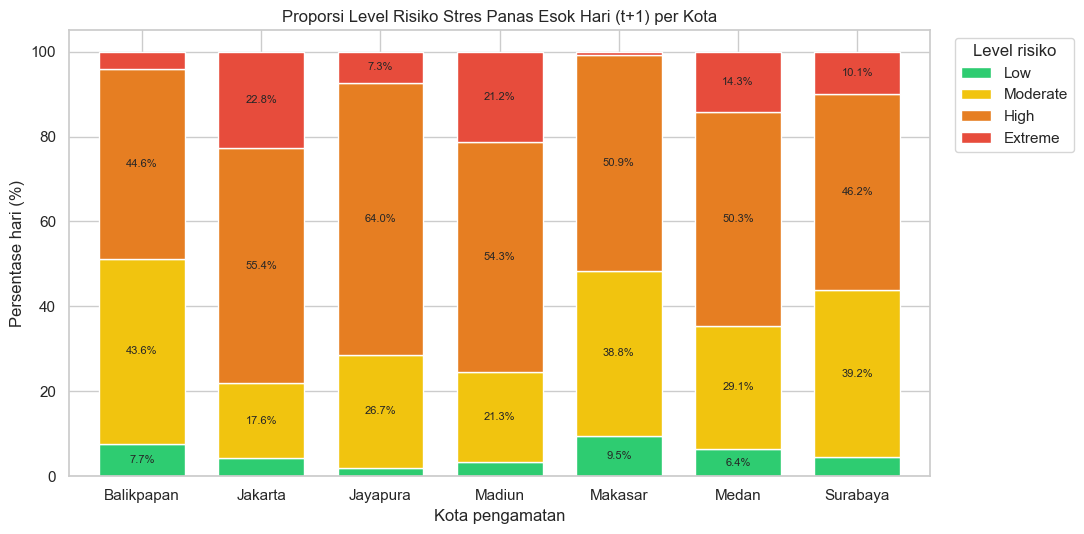

heat_risk_besok,Low,Moderate,High,Extreme
kota,,,,
Balikpapan,7.67,43.57,44.65,4.11
Jakarta,4.21,17.63,55.35,22.81
Jayapura,1.87,26.74,64.05,7.34
Madiun,3.23,21.32,54.28,21.18
Makasar,9.54,38.76,50.86,0.84
Medan,6.36,29.08,50.26,14.31
Surabaya,4.53,39.22,46.19,10.05


In [4]:
bins_tropis = [-np.inf, 33.0, 36.0, 39.0, np.inf]
labels_risk = ["Low", "Moderate", "High", "Extreme"]
df_eda = df.dropna(subset=["target_apparent_temp_besok"]).copy()
df_eda["heat_risk_besok"] = pd.cut(
    df_eda["target_apparent_temp_besok"],
    bins=bins_tropis,
    labels=labels_risk,
    right=False,
)

sns.set_theme(style="whitegrid", context="notebook")
city_distribution = pd.crosstab(df_eda["kota"], df_eda["heat_risk_besok"], normalize="index").reindex(columns=labels_risk) * 100
ax = city_distribution.plot(
    kind="bar", stacked=True, figsize=(11, 5.5),
    color=["#2ecc71", "#f1c40f", "#e67e22", "#e74c3c"],
    edgecolor="white", width=0.72,
)
ax.set(title="Proporsi Level Risiko Stres Panas Esok Hari (t+1) per Kota",
       xlabel="Kota pengamatan", ylabel="Persentase hari (%)", ylim=(0, 105))
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Level risiko", bbox_to_anchor=(1.02, 1), loc="upper left")
for container in ax.containers:
    values = [f"{bar.get_height():.1f}%" if bar.get_height() >= 6 else "" for bar in container]
    ax.bar_label(container, labels=values, label_type="center", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "eda_1_distribusi_risiko_per_kota.png", dpi=300, bbox_inches="tight")
plt.show()
display(city_distribution.round(2))

**Insight:** Kelas `High` mendominasi di sebagian besar kota, tetapi proporsi `Extreme` dan `Low` berbeda menurut lokasi. Oleh karena itu, lokasi kota perlu dipertahankan sebagai fitur kategorikal dan ketimpangan kelas ditangani pada tahap pelatihan, bukan dengan mengubah urutan waktu.

## EDA 2: apparent temperature menurut fase ENSO

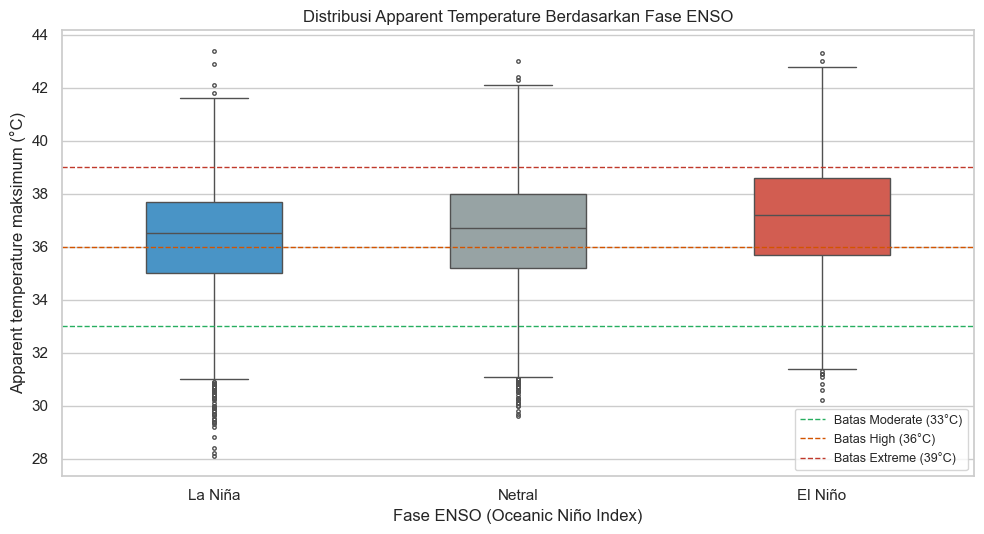

,Jumlah,Mean,Median,Q25,Q75,Maksimum
enso_label,,,,,,
La Niña,5110,36.24,36.5,35.0,37.7,43.4
Netral,6167,36.53,36.7,35.2,38.0,43.0
El Niño,3696,37.09,37.2,35.7,38.6,43.3


In [5]:
enso_labels = {-1.0: "La Niña", 0.0: "Netral", 1.0: "El Niño"}
df_eda["enso_label"] = df_eda["enso_phase"].map(enso_labels)
enso_order = ["La Niña", "Netral", "El Niño"]
palette_enso = {"La Niña": "#3498db", "Netral": "#95a5a6", "El Niño": "#e74c3c"}

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(
    data=df_eda, x="enso_label", y="apparent_temp_max",
    order=enso_order, hue="enso_label", hue_order=enso_order,
    palette=palette_enso, dodge=False, legend=False, width=0.45,
    fliersize=2.5, ax=ax,
)
for threshold, color, label in [
    (33, "#27ae60", "Batas Moderate (33°C)"),
    (36, "#d35400", "Batas High (36°C)"),
    (39, "#c0392b", "Batas Extreme (39°C)"),
]:
    ax.axhline(threshold, color=color, linestyle="--", linewidth=1, label=label)
ax.set(title="Distribusi Apparent Temperature Berdasarkan Fase ENSO",
       xlabel="Fase ENSO (Oceanic Niño Index)", ylabel="Apparent temperature maksimum (°C)")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "eda_2_apparent_temp_vs_enso.png", dpi=300, bbox_inches="tight")
plt.show()

enso_stats = df_eda.groupby("enso_label", observed=False)["apparent_temp_max"].agg(
    Jumlah="count", Mean="mean", Median="median", Q25=lambda s: s.quantile(.25),
    Q75=lambda s: s.quantile(.75), Maksimum="max",
).reindex(enso_order)
display(enso_stats.round(2))

**Insight:** Sebaran suhu terasa bergeser ke nilai yang lebih tinggi pada fase El Niño. Indikator ENSO lagged layak dipertahankan sebagai konteks iklim, tetapi indeks bulan berjalan tidak digunakan sebagai masukan model karena jeda ketersediaan operasional.

## EDA 3: korelasi cuaca, ONI historis, dan target

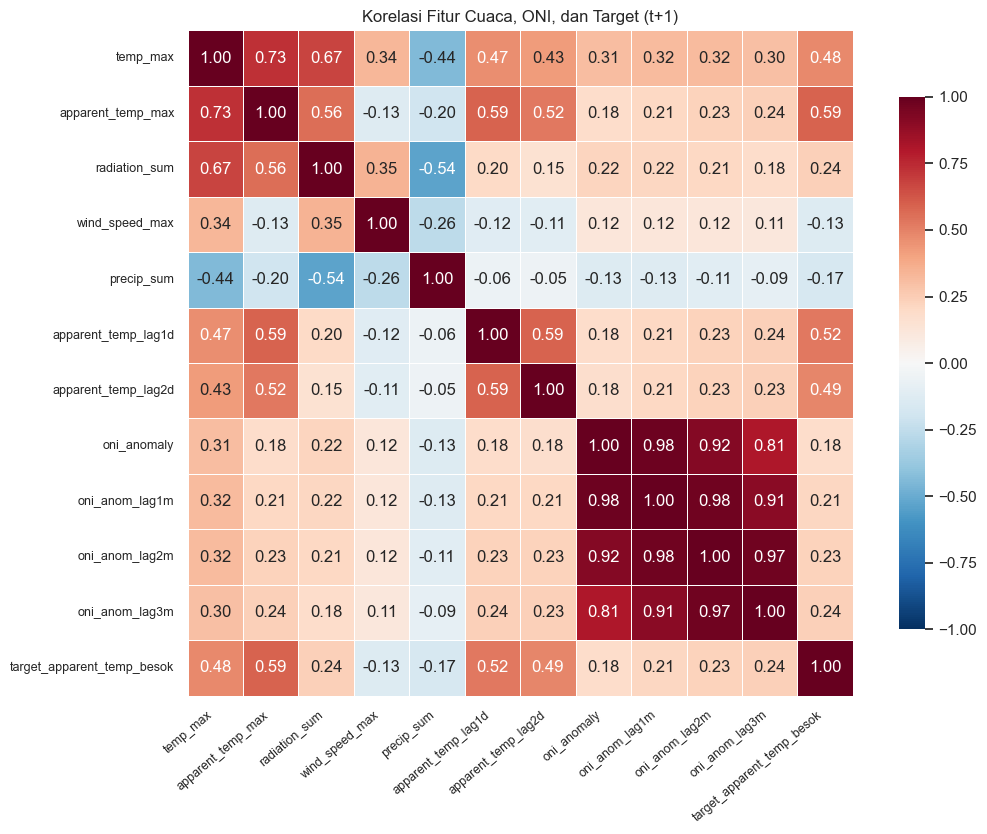

,Korelasi dengan target
apparent_temp_max,0.588080
apparent_temp_lag1d,0.524709
apparent_temp_lag2d,0.485416
temp_max,0.484074
radiation_sum,0.240358
oni_anom_lag3m,0.236680
oni_anom_lag2m,0.231217
oni_anom_lag1m,0.211799
oni_anomaly,0.184937
wind_speed_max,-0.133694


In [6]:
correlation_features = [
    "temp_max", "apparent_temp_max", "radiation_sum", "wind_speed_max",
    "precip_sum", "apparent_temp_lag1d", "apparent_temp_lag2d",
    "oni_anomaly", "oni_anom_lag1m", "oni_anom_lag2m", "oni_anom_lag3m",
    "target_apparent_temp_besok",
]
corr_matrix = df_eda[correlation_features].corr()
fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
    vmin=-1, vmax=1, square=True, linewidths=.5,
    cbar_kws={"shrink": .8}, ax=ax,
)
ax.set_title("Korelasi Fitur Cuaca, ONI, dan Target (t+1)")
plt.xticks(rotation=40, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "eda_3_heatmap_korelasi.png", dpi=300, bbox_inches="tight")
plt.show()
display(corr_matrix["target_apparent_temp_besok"].drop("target_apparent_temp_besok").sort_values(ascending=False).to_frame("Korelasi dengan target"))

**Insight:** Fitur suhu terasa saat ini dan lag hariannya memperlihatkan keterkaitan temporal dengan target besok. ONI lagged mewakili dampak iklim yang tertunda, sedangkan curah hujan dan angin dapat berkaitan dengan pendinginan. Korelasi bersifat deskriptif dan bukan bukti sebab-akibat.

## Ringkasan keputusan untuk data preparation

- Ambang kelas tropis `[-∞, 33, 36, 39, ∞)` dengan `right=False` dipakai karena kalibrasi subtropis membuat kelas Low kosong.
- 28 baris NaN berasal dari lag dan target di batas rentang; baris tersebut dihapus. Outlier cuaca/ONI yang valid dipertahankan.
- Fitur target masa depan serta `oni_anomaly` dan `oni_sst_total` bulan berjalan dikeluarkan dari input.
- Semua lag/window dibuat atau diproses per kota; split berdasarkan waktu: train sampai 2024, validation 2025, test mulai 2026.
- Encoding/scaling dipelajari dari train; class weighting dihitung hanya dari label train.